In [3]:
import json
import matplotlib.pyplot as plt
import numpy as np

In [4]:
split = "train"  # choisir le split: "train", "val", "test"
crop_size = 32

In [5]:
# recharger le dictionnaire depuis le fichier JSON
with open(f'data/dataset_attributs/{split}_{crop_size}x{crop_size}_donnees.json', 'r', encoding='utf-8') as f:
    donnees = json.load(f)

In [6]:
# compter le nombre d'éléments dans le jeu de données

nombre_elements = sum([len(crops) for crops in donnees.values()])
print(f"Nombre total d'éléments dans le jeu de données : {nombre_elements}")

Nombre total d'éléments dans le jeu de données : 455135


Nombre de carrés par catégorie de dégât :
Catégorie 0: 350665 carrés
Catégorie 1: 2621 carrés
Catégorie 2: 17760 carrés
Catégorie 3: 33582 carrés
Catégorie 4: 50507 carrés


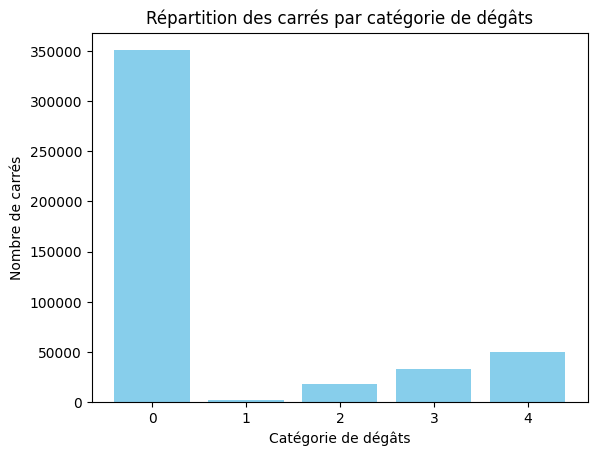

In [7]:
# compter le nombre de carrés par catégorie de dégât
nb_carre = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}
for _, crops in donnees.items():
    for crop in crops:
        if "damage" in crop:
            damage = crop["damage"]
            class_index = damage
            if class_index is not None:
                nb_carre[class_index] += 1

print("Nombre de carrés par catégorie de dégât :")
for k, v in nb_carre.items():
    print(f"Catégorie {k}: {v} carrés")


# Affichage histogramme
categories = list(nb_carre.keys())
counts = list(nb_carre.values())

plt.bar(categories, counts, color='skyblue')
plt.xlabel("Catégorie de dégâts")
plt.ylabel("Nombre de carrés")
plt.title("Répartition des carrés par catégorie de dégâts")
plt.xticks(categories)
plt.show()

/home/infres/cherr-24/virtual_environments/env1/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


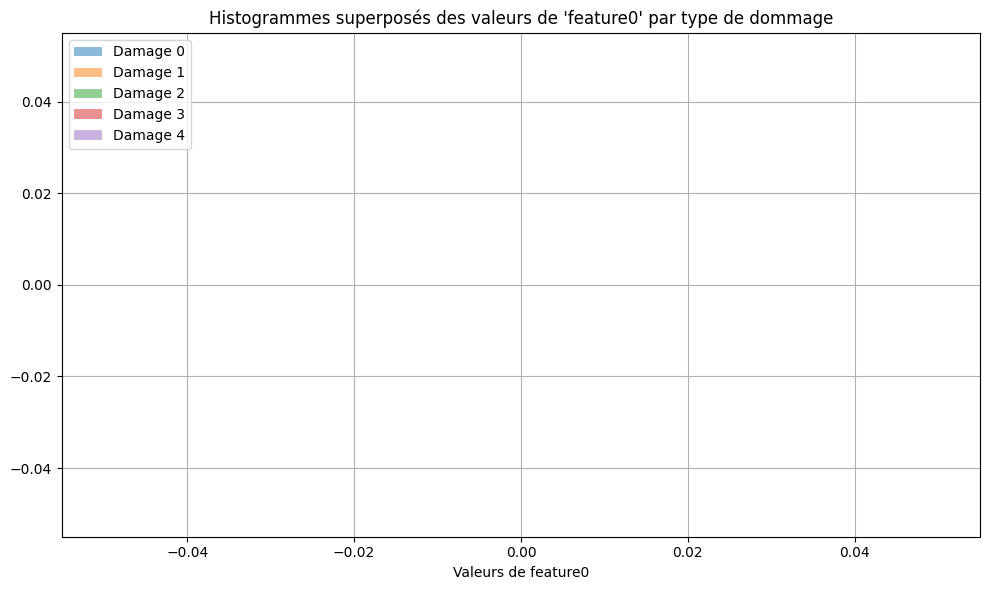

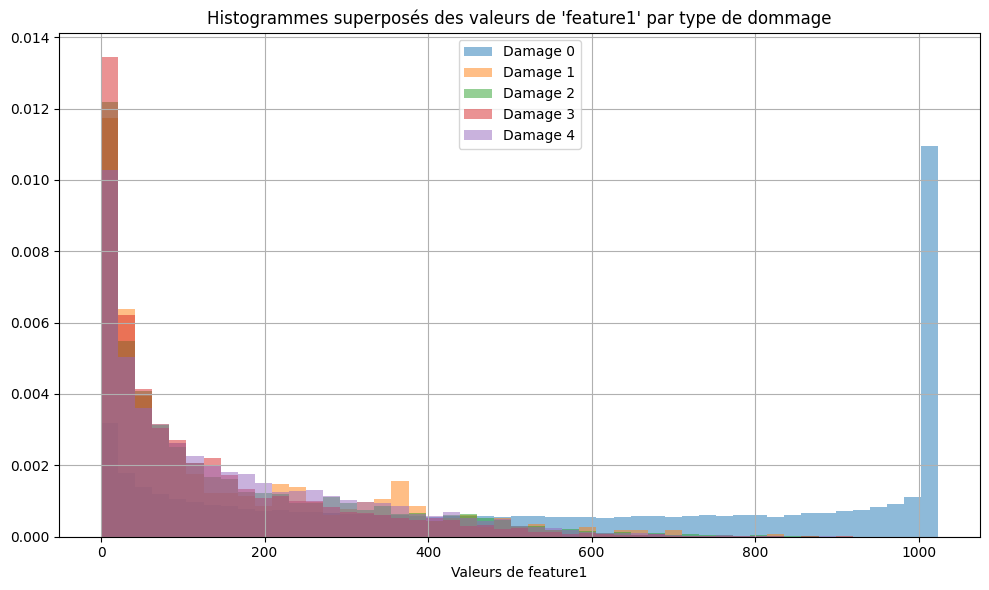

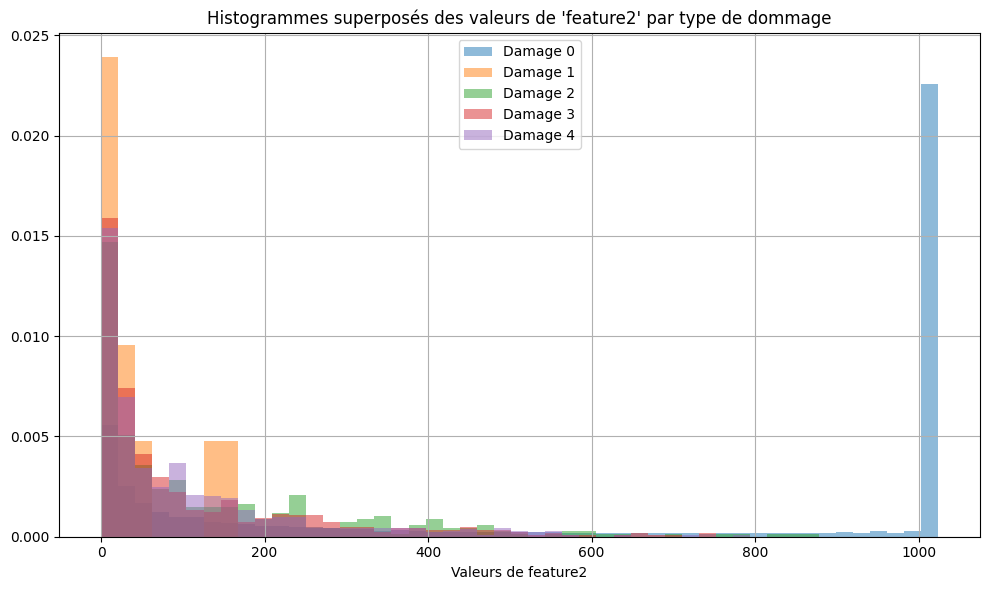

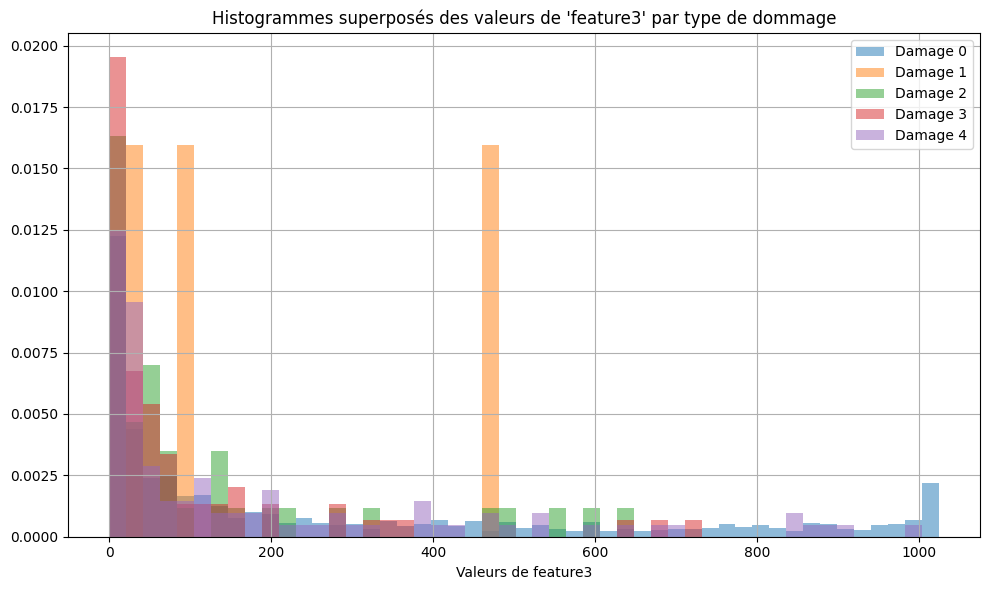

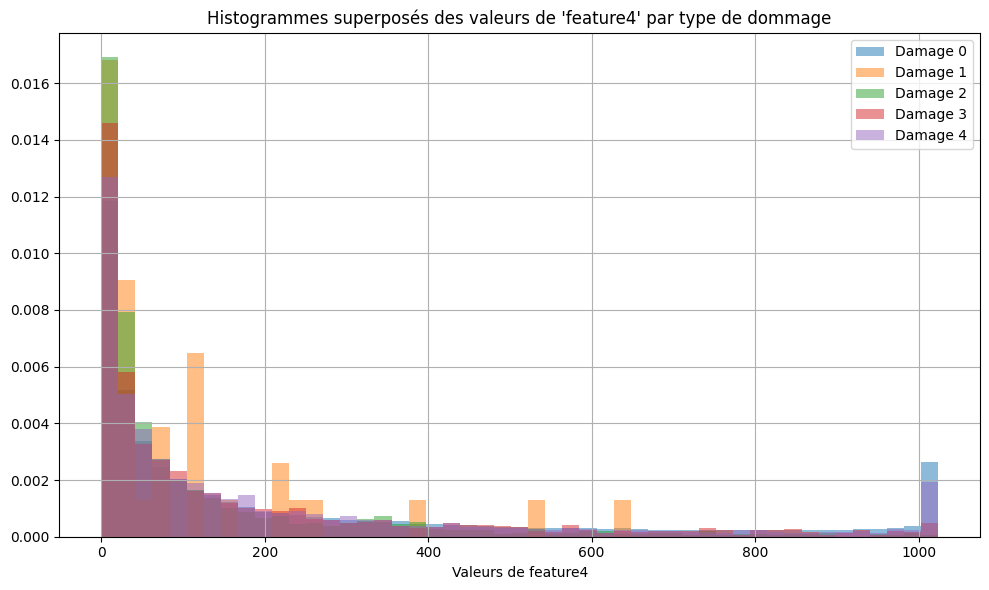

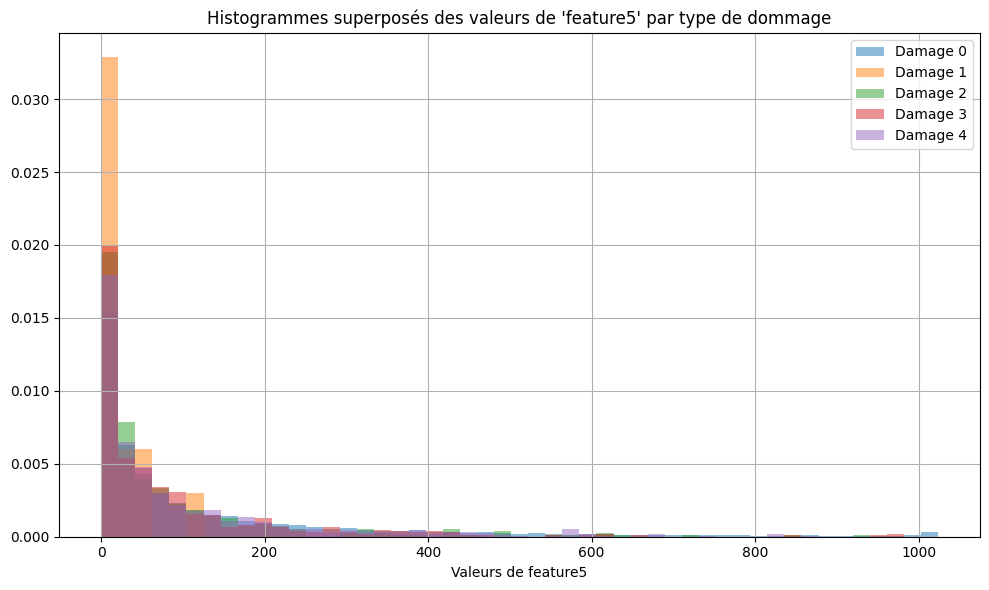

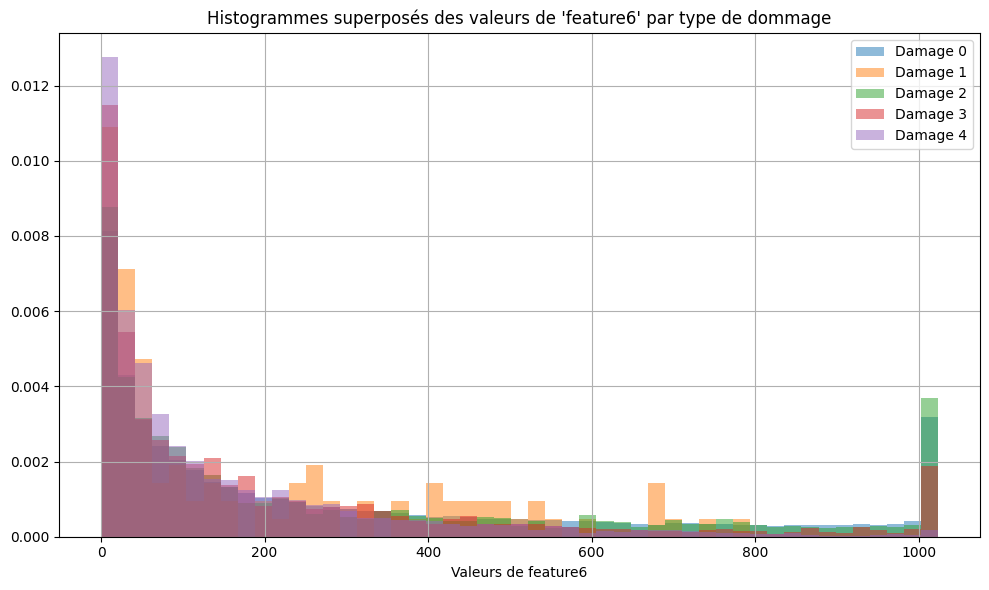

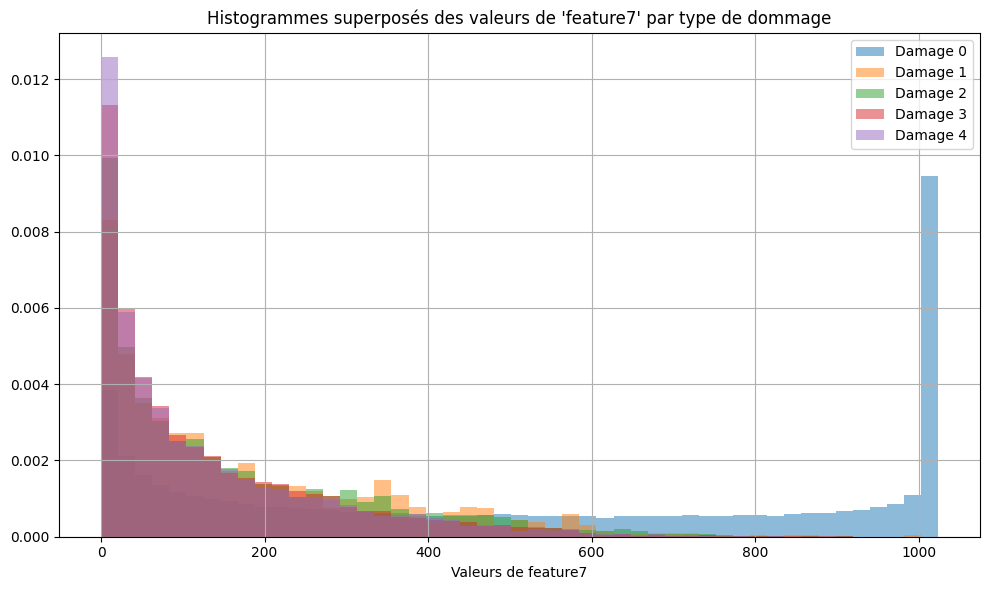

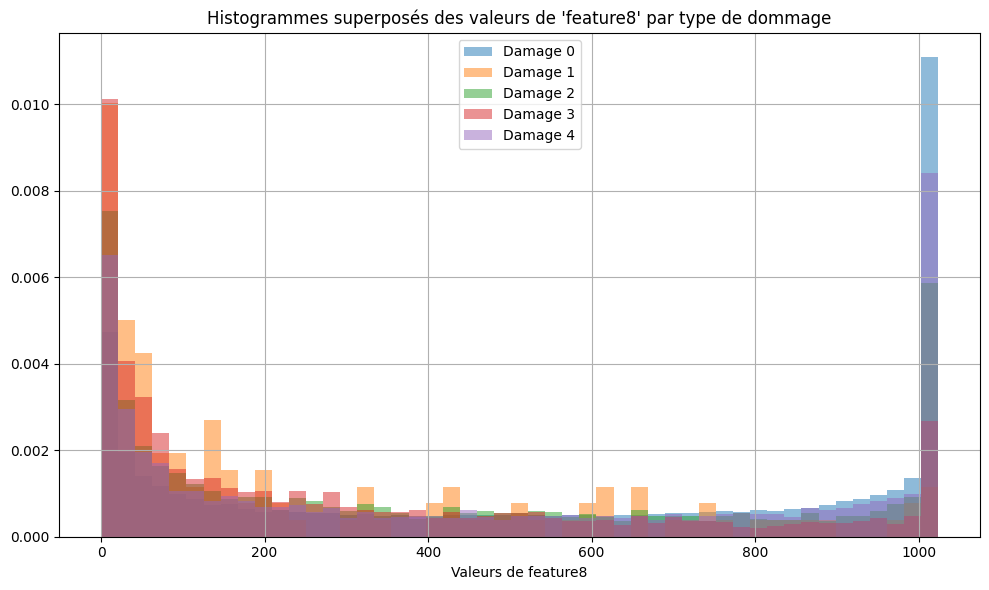

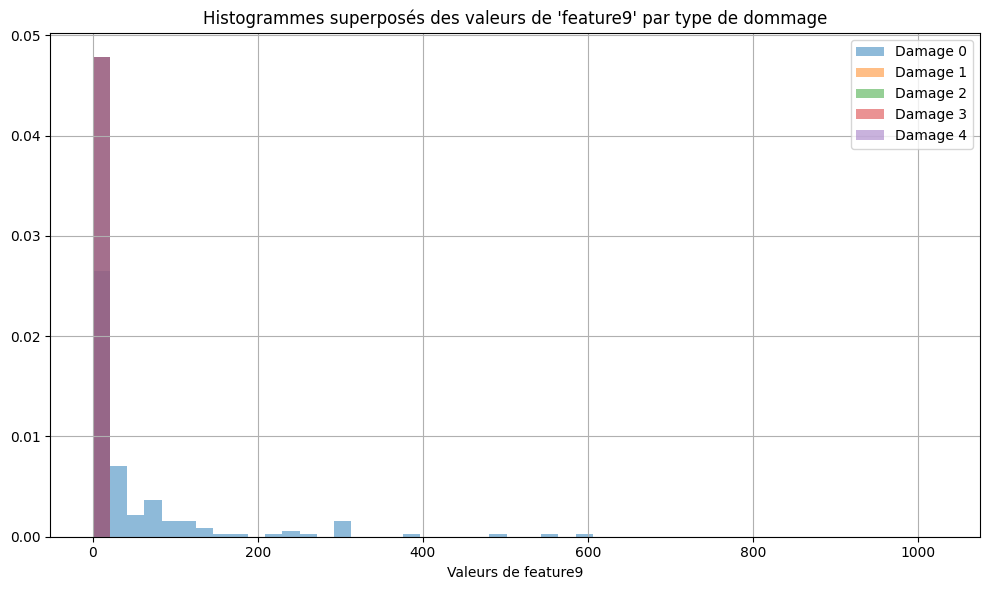

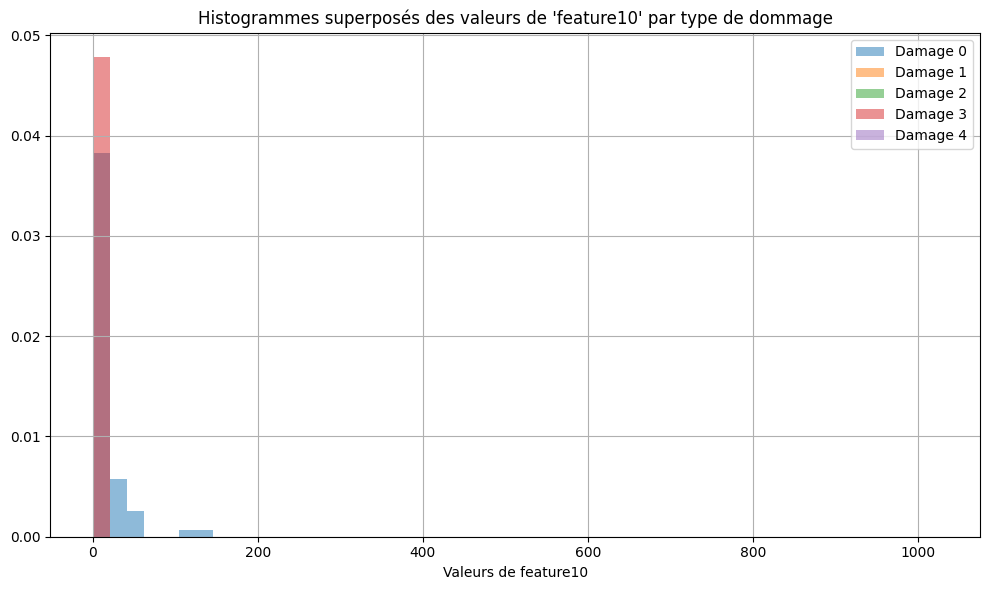

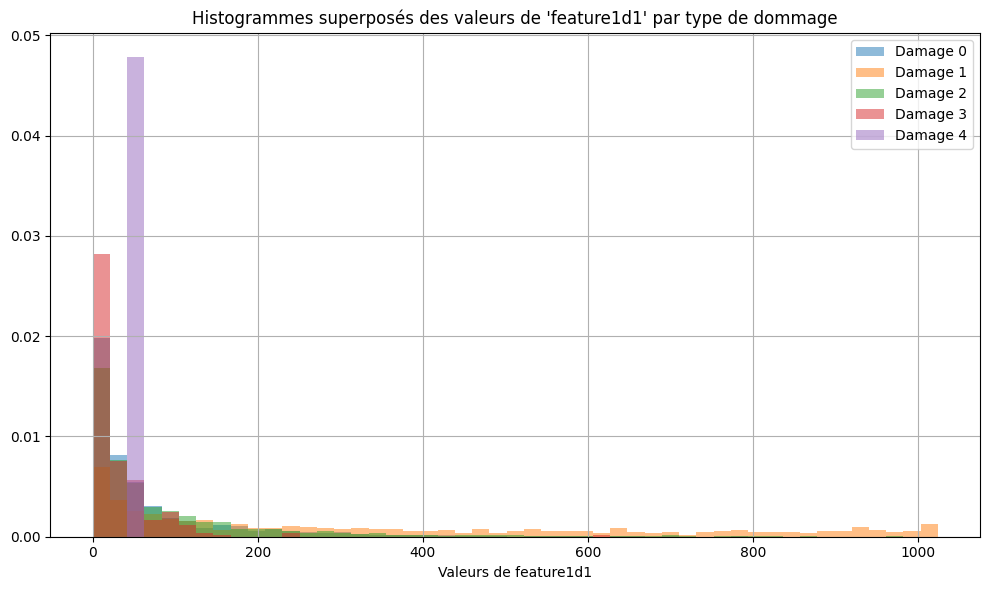

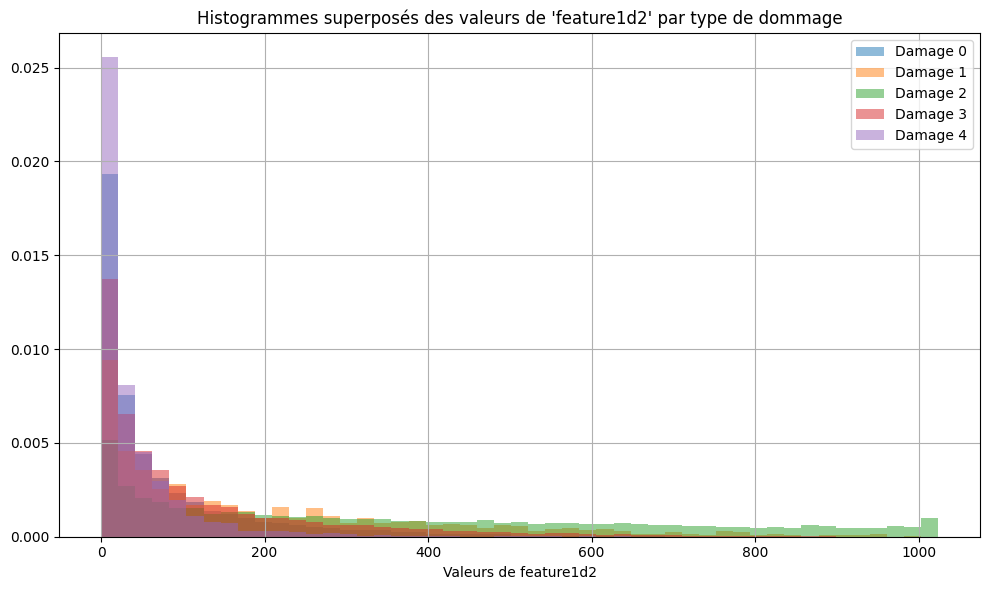

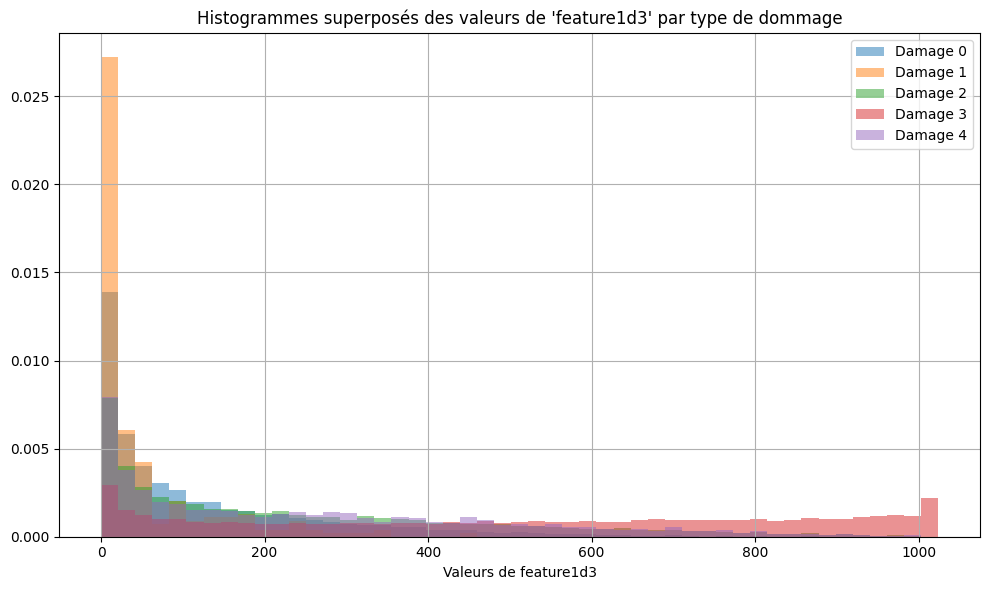

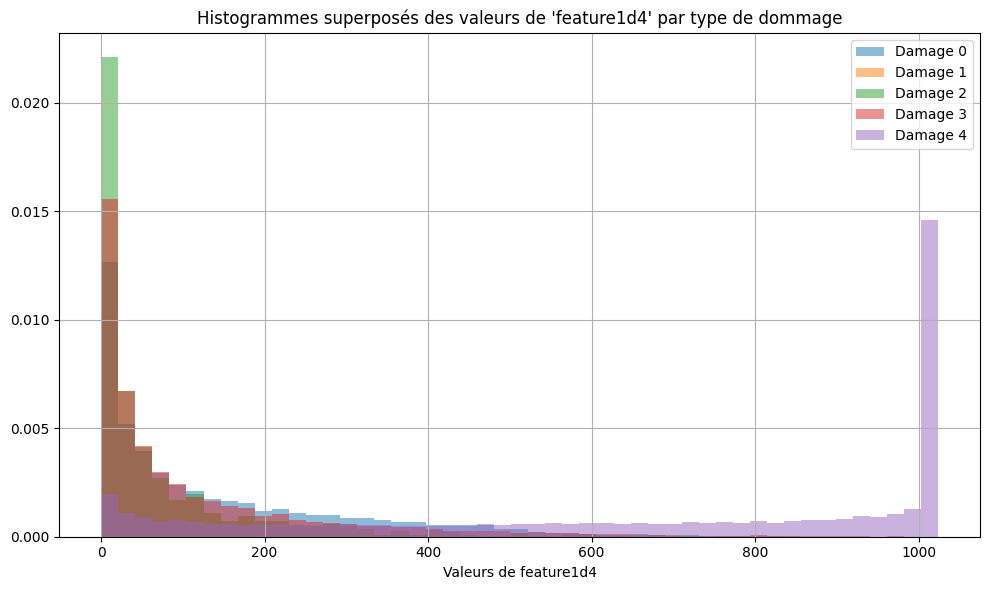

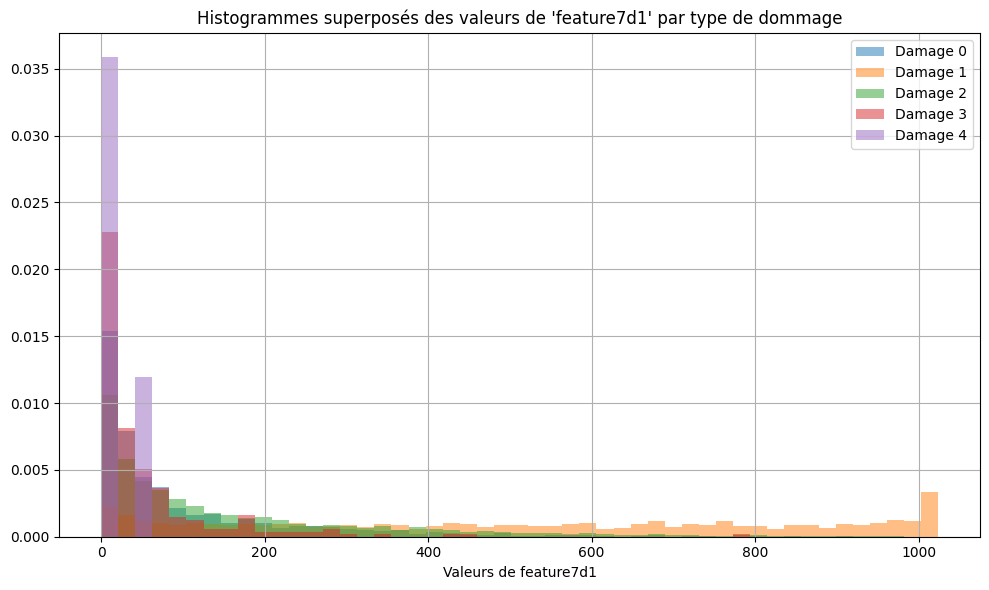

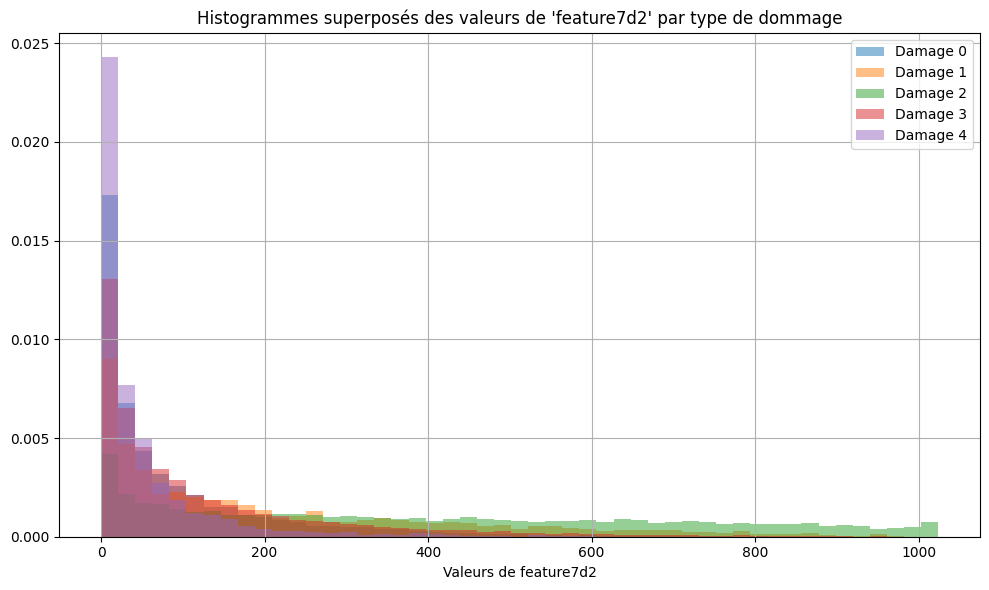

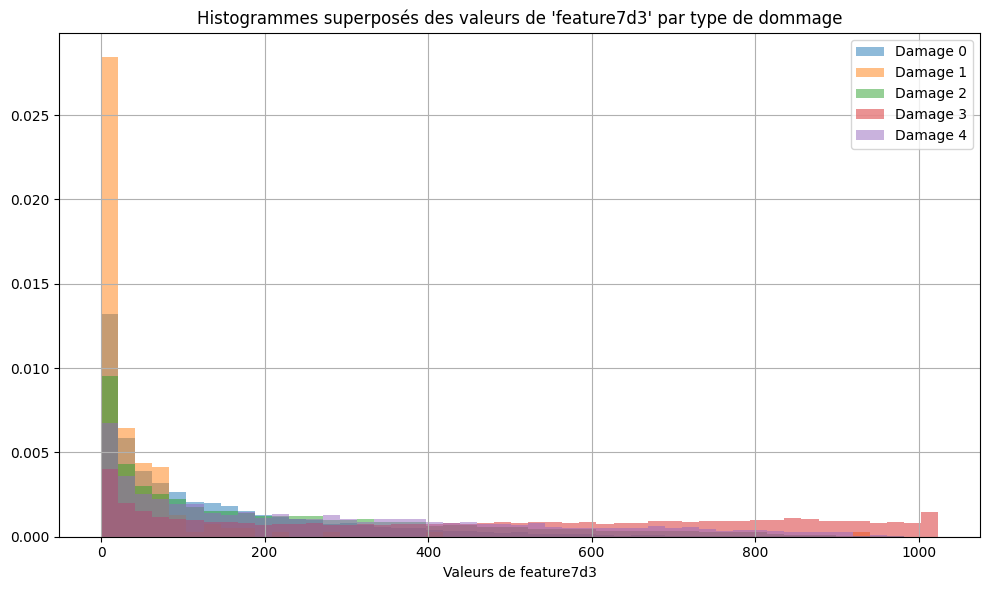

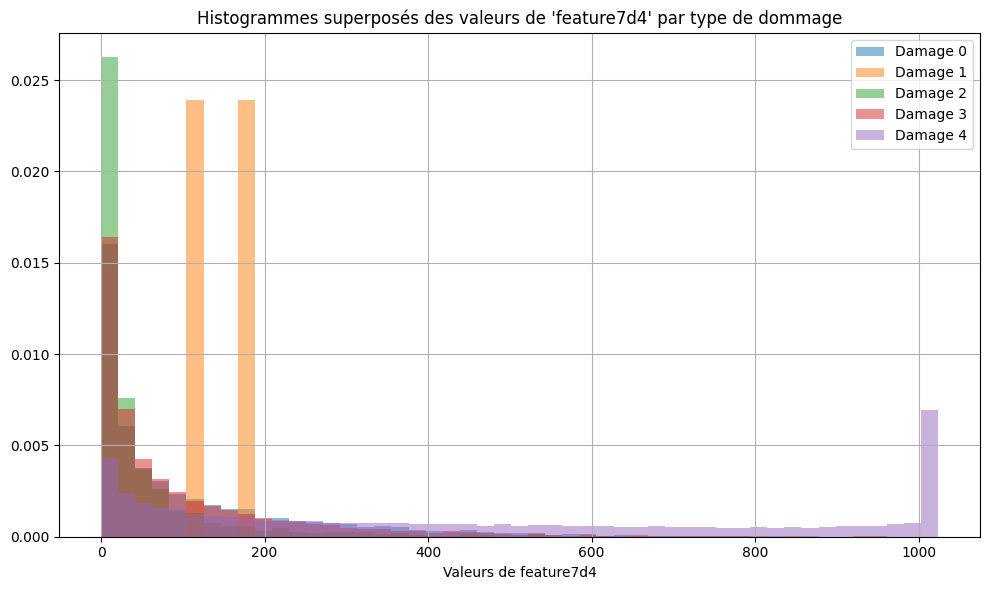

In [8]:
# déterminer la répartition des features

for feature in ["feature0", "feature1", "feature2", "feature3", "feature4", "feature5", "feature6", "feature7", "feature8", "feature9", "feature10", "feature1d1", "feature1d2", "feature1d3", "feature1d4", "feature7d1", "feature7d2", "feature7d3", "feature7d4"]:

    l0, l1, l2, l3, l4 = [], [], [], [], []

    for path, crops in donnees.items():
        for crop in crops:
            if feature in crop:
                damage = crop["damage"]
                if damage == 0:
                    l0.append(crop[feature])
                elif damage == 1:
                    l1.append(crop[feature])
                elif damage == 2:
                    l2.append(crop[feature])
                elif damage == 3:
                    l3.append(crop[feature])
                elif damage == 4:
                    l4.append(crop[feature])


    # Tracer les histogrammes superposés avec mêmes bins
    plt.figure(figsize=(10, 6))
    bin_edges = np.linspace(0, 1024, 50) # 10 bins from 0 to 1024
    plt.hist(l0, bins=bin_edges, alpha=0.5, label="Damage 0", density=True)
    plt.hist(l1, bins=bin_edges, alpha=0.5, label="Damage 1", density=True)
    plt.hist(l2, bins=bin_edges, alpha=0.5, label="Damage 2", density=True)
    plt.hist(l3, bins=bin_edges, alpha=0.5, label="Damage 3", density=True)
    plt.hist(l4, bins=bin_edges, alpha=0.5, label="Damage 4", density=True)

    # plt.xticks(bin_edges, rotation=45)
    plt.xlabel(f"Valeurs de {feature}")
    plt.title(f"Histogrammes superposés des valeurs de '{feature}' par type de dommage")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
